### Thư viện

In [1]:
import torch
import numpy as np 
import pandas as pd 
import sklearn
import os
import random
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F

In [109]:
def set_seed(seed: int = 42, deterministic: bool = True):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  

    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
        torch.use_deterministic_algorithms(True, warn_only=True)


def get_device(prefer: str = "auto") -> torch.device:
    if prefer == "cpu":
        return torch.device("cpu")
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():  
        return torch.device("mps")
    return torch.device("cpu")

In [110]:
SEED = 42
set_seed(SEED)
device = get_device()
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cpu


In [111]:
data = pd.read_csv("data\\auto-mpg.csv")
data

,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70
...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82
394,44.0,4,97.0,52.0,2130,24.6,82
395,32.0,4,135.0,84.0,2295,11.6,82
396,28.0,4,120.0,79.0,2625,18.6,82


In [112]:
# Kiểm tra missing value
print(data.isna().sum())

# Xóa các dòng có missing value
data = data.dropna().reset_index(drop=True)

# Tách features và target
X = data.drop(columns=["mpg"])
y = data["mpg"]

mpg             0
cylinders       0
displacement    0
horsepower      2
weight          0
acceleration    0
model-year      0
dtype: int64


In [113]:
from sklearn.model_selection import train_test_split

# 70% train, 20% val, 10% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=1/3, random_state=SEED
)

In [114]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


In [115]:
print(X_train.shape)
print(y_train.shape)

print(X_train.dtype)
print(y_train.dtype)

(277, 6)
(277,)
float64
float64


In [116]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_val = torch.tensor(y_val.to_numpy(), dtype=torch.float32)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

In [117]:
class CustomDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [118]:
train_dataset = CustomDataset(X_train, y_train)
val_dataset = CustomDataset(X_val, y_val)
test_dataset = CustomDataset(X_test, y_test)

In [119]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [120]:
class MLP(nn.Module):
    def __init__(self, input_dims, hidden_dims):
        super().__init__()

        self.fc1 = nn.Linear(input_dims, hidden_dims)
        self.fc2 = nn.Linear(hidden_dims, hidden_dims)
        self.fc3 = nn.Linear(hidden_dims, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x.squeeze(1)


In [121]:
input_dims = X_train.shape[1]
hidden_dims = 64

model = MLP(
    input_dims=input_dims,
    hidden_dims=hidden_dims
)

In [122]:
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)
def r_squared(y_true, y_pred):
    ss_res = torch.sum((y_true - y_pred) ** 2)

    y_mean = torch.mean(y_true)
    ss_tot = torch.sum((y_true - y_mean) ** 2)

    return 1 - ss_res / ss_tot

In [123]:
epochs = 1000

train_losses = []
val_losses = []

train_r2_scores = []
val_r2_scores = []

for epoch in range(epochs):

    # TRAIN
    model.train()

    train_loss = 0
    train_preds = []
    train_targets = []

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        y_pred = model(X_batch)

        loss = criterion(y_pred, y_batch)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

        train_preds.append(y_pred.detach())
        train_targets.append(y_batch.detach())

    train_loss /= len(train_loader)

    train_preds = torch.cat(train_preds)
    train_targets = torch.cat(train_targets)

    train_r2 = r_squared(train_targets, train_preds)

    train_losses.append(train_loss)
    train_r2_scores.append(train_r2.item())


    # VALIDATION
    model.eval()

    val_loss = 0
    val_preds = []
    val_targets = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            y_pred = model(X_batch)

            loss = criterion(y_pred, y_batch)

            val_loss += loss.item()

            val_preds.append(y_pred)
            val_targets.append(y_batch)

    val_loss /= len(val_loader)

    val_preds = torch.cat(val_preds)
    val_targets = torch.cat(val_targets)

    val_r2 = r_squared(val_targets, val_preds)

    val_losses.append(val_loss)
    val_r2_scores.append(val_r2.item())


    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train R2: {train_r2:.4f} | "
        f"Val R2: {val_r2:.4f}"
    )

Epoch 1/1000 | Train Loss: 537.8362 | Val Loss: 419.1106 | Train R2: -7.2466 | Val R2: -7.5224
Epoch 2/1000 | Train Loss: 305.1418 | Val Loss: 324.6658 | Train R2: -3.6405 | Val R2: -5.6000
Epoch 3/1000 | Train Loss: 159.7334 | Val Loss: 28.7223 | Train R2: -1.5445 | Val R2: 0.4758
Epoch 4/1000 | Train Loss: 28.2683 | Val Loss: 36.1459 | Train R2: 0.5806 | Val R2: 0.3398
Epoch 5/1000 | Train Loss: 17.4170 | Val Loss: 17.7987 | Train R2: 0.7287 | Val R2: 0.6888
Epoch 6/1000 | Train Loss: 17.4693 | Val Loss: 49.8405 | Train R2: 0.7465 | Val R2: 0.0518
Epoch 7/1000 | Train Loss: 22.0600 | Val Loss: 13.7235 | Train R2: 0.6508 | Val R2: 0.7722
Epoch 8/1000 | Train Loss: 10.1153 | Val Loss: 15.6405 | Train R2: 0.8444 | Val R2: 0.7257
Epoch 9/1000 | Train Loss: 14.4591 | Val Loss: 10.6606 | Train R2: 0.7759 | Val R2: 0.8221
Epoch 10/1000 | Train Loss: 9.2153 | Val Loss: 15.4107 | Train R2: 0.8629 | Val R2: 0.7305
Epoch 11/1000 | Train Loss: 12.6177 | Val Loss: 13.1309 | Train R2: 0.8033 | Val

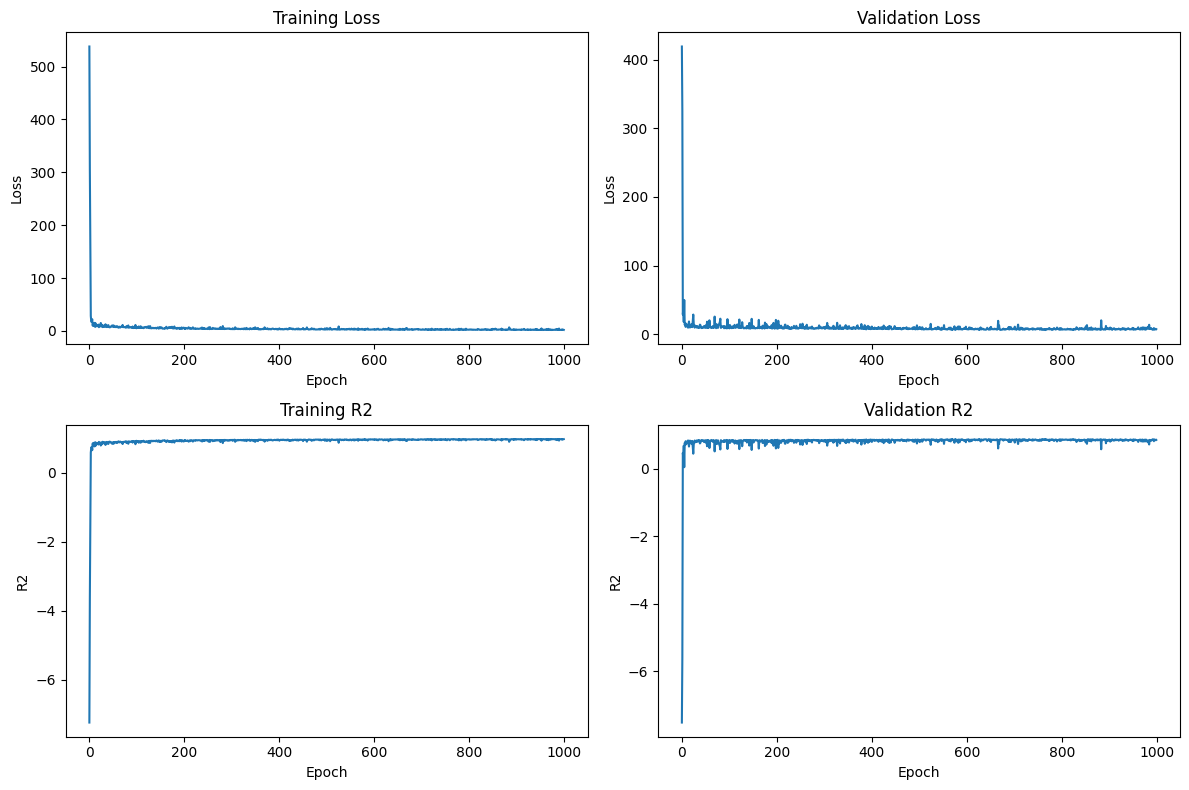

In [124]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.plot(train_losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(2, 2, 2)
plt.plot(val_losses)
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(2, 2, 3)
plt.plot(train_r2_scores)
plt.title("Training R2")
plt.xlabel("Epoch")
plt.ylabel("R2")

plt.subplot(2, 2, 4)
plt.plot(val_r2_scores)
plt.title("Validation R2")
plt.xlabel("Epoch")
plt.ylabel("R2")

plt.tight_layout()
plt.show()

In [ ]:
model.eval()

test_preds = []
test_targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        y_pred = model(X_batch)

        test_preds.append(y_pred)
        test_targets.append(y_batch)

test_preds = torch.cat(test_preds)
test_targets = torch.cat(test_targets)

test_r2 = r_squared(test_targets, test_preds)

print("Test R2:", test_r2.item())

Test R2: 0.8273488283157349


In [126]:
for i in range(10):
    print(
        f"True MPG: {test_targets[i].item():.2f} | "
        f"Predicted MPG: {test_preds[i].item():.2f}"
    )

True MPG: 34.40 | Predicted MPG: 35.17
True MPG: 16.00 | Predicted MPG: 15.58
True MPG: 27.00 | Predicted MPG: 26.37
True MPG: 13.00 | Predicted MPG: 13.18
True MPG: 21.00 | Predicted MPG: 18.52
True MPG: 15.00 | Predicted MPG: 13.34
True MPG: 15.00 | Predicted MPG: 13.38
True MPG: 15.00 | Predicted MPG: 13.27
True MPG: 34.00 | Predicted MPG: 28.66
True MPG: 18.00 | Predicted MPG: 28.40
